In [ ]:
import torch as torch
import numpy as np
import matplotlib.pyplot as plt
import copy as copy
import torchvision.transforms as T

from torch import nn
from functools import partial
from torchvision.datasets import FashionMNIST
from torch.utils.data import DataLoader, random_split
from torchmetrics.classification import Accuracy, ConfusionMatrix

In [ ]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

In [ ]:
train_dataset = FashionMNIST(root='data', train=True, download=True, transform=T.ToTensor())
test_dataset = FashionMNIST(root='data', train=False, download=True, transform=T.ToTensor())
len(train_dataset), len(test_dataset)

(60000, 10000)

In [ ]:
train_dataset, valid_dataset = random_split(train_dataset, [50_000, 10_000])
len(train_dataset), len(valid_dataset)

(50000, 10000)

In [ ]:
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [ ]:
img, l = next(iter(train_loader))
img.shape

torch.Size([64, 1, 28, 28])

In [ ]:
#previously i got around 87% accuracy

In [ ]:
conv_fn = partial(nn.Conv2d, kernel_size=3, padding='same', stride=1)
max_pool_fn = partial(nn.MaxPool2d, kernel_size=2, stride=2)

def initialize(m):
  if isinstance(m, (nn.Conv2d, nn.Linear)):
    nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
    if m.bias is not None:
      nn.init.zeros_(m.bias)

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            conv_fn(in_channels=1, out_channels=4), nn.ReLU(), max_pool_fn(),
        )
    def forward(self, X):
      return self.layers(X)

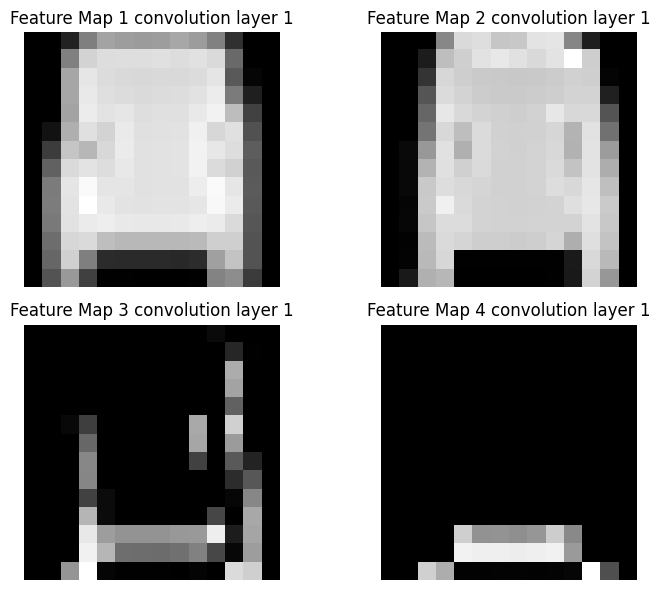

In [ ]:
img1, label = next(iter(train_loader))

model = CNN()
model.apply(initialize)
model(img1[0]).shape

fig, ax = plt.subplots(2, 2, figsize=(8, 6))
ax = ax.ravel()
for i in range(4):
  ax[i].imshow(model(img1[0])[i].detach().numpy(), cmap='gray')
  ax[i].axis('off')
  ax[i].set_title(f'Feature Map {i+1} convolution layer 1')
plt.tight_layout()
plt.show()

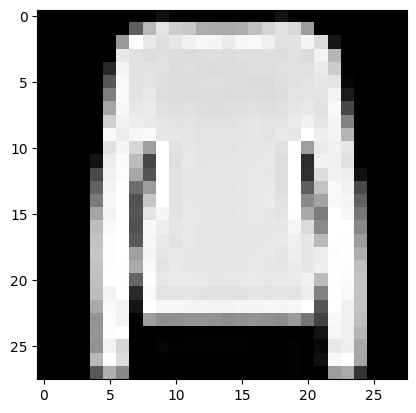

In [ ]:
plt.figure()
plt.imshow(img1[0][0], cmap='gray')
plt.show()

In [ ]:
#Creating CNN Architecture

conv_fn = partial(nn.Conv2d, kernel_size=3, padding='same', stride=1)
max_pool_fn = partial(nn.MaxPool2d, kernel_size=2, stride=2)

def initialize(m):
  if isinstance(m, (nn.Conv2d, nn.Linear)):
    nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
    if m.bias is not None:
      nn.init.zeros_(m.bias)

def conv_block(in_channels, out_channels):
  return nn.Sequential(
      conv_fn(in_channels=in_channels, out_channels=out_channels, bias=False),
      nn.BatchNorm2d(num_features=out_channels),
      nn.ReLU(),
      max_pool_fn()
  )

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            conv_block(in_channels=1, out_channels=16),
            conv_block(in_channels=16, out_channels=32),
            nn.Flatten(),
            nn.Linear(in_features=1568, out_features=32, bias=False),
            nn.BatchNorm1d(num_features=32),
            nn.ReLU(),
            nn.Dropout(p=0.5),
            nn.Linear(in_features=32, out_features=10, bias=True)
        )
    def forward(self, X):
      return self.layers(X)

model = CNN().to(device).apply(initialize)
model

CNN(
  (layers): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=same, bias=False)
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=same, bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Flatten(start_dim=1, end_dim=-1)
    (3): Linear(in_features=1568, out_features=32, bias=False)
    (4): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): Dropout(p=0.5, inplace=False)
    (7): Linear(in_features=32, out_features=10, bias=True)
  )
)

In [ ]:
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-2, weight_decay=0.01)
loss_function = nn.CrossEntropyLoss()
epochs = 15
steps = len(train_loader)
warmup_steps = steps
total_steps = epochs * steps

warmup = torch.optim.lr_scheduler.LinearLR(
    optimizer, start_factor=0.001, end_factor=1.0, total_iters=warmup_steps)
cosine = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=total_steps - warmup_steps, eta_min=1e-6)
scheduler = torch.optim.lr_scheduler.SequentialLR(
    optimizer, schedulers=[warmup, cosine], milestones=[warmup_steps])

#Training the model

best_val = float('inf')
best_state = None
patience = 4
bad_epochs = 0
min_delta = 1e-3

train_loss, valid_loss = [], []
lr_history = []

for epoch in range(epochs):
  model.train()
  epoch_train_loss = 0
  epoch_valid_loss = 0
  for X_train, y_train in train_loader:
    X_train, y_train = X_train.to(device), y_train.to(device)
    y_pred = model(X_train)
    loss = loss_function(y_pred, y_train)
    optimizer.zero_grad()
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    optimizer.step()
    scheduler.step()
    epoch_train_loss += loss.item()
    lr_history.append(optimizer.param_groups[0]['lr'])

  model.eval()
  for X_valid, y_valid in valid_loader:
    with torch.inference_mode():
      X_valid, y_valid = X_valid.to(device), y_valid.to(device)
      y_pred = model(X_valid)
      loss = loss_function(y_pred, y_valid)
      epoch_valid_loss += loss.item()
  train_loss.append(epoch_train_loss/len(train_loader))
  valid_loss.append(epoch_valid_loss/len(valid_loader))
  if valid_loss[-1] < best_val - min_delta:
    best_val = valid_loss[-1]
    best_state = copy.deepcopy(model.state_dict())
    torch.save(best_state, 'best_model.pt')
    bad_epochs = 0
  else:
    bad_epochs += 1
    if bad_epochs >= patience:
      print(f'Early stopping at epoch {epoch+1}, best val loss {best_val:.4f}')
      break

model.load_state_dict(best_state)


<All keys matched successfully>

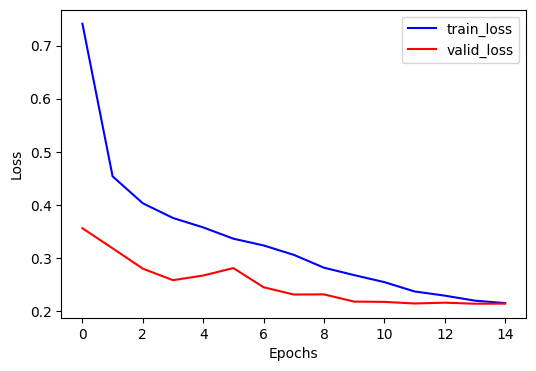

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(train_loss, label='train_loss', color='blue')
plt.plot(valid_loss, label='valid_loss', color='red')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

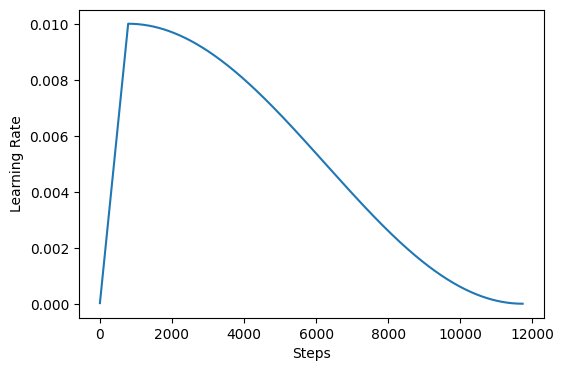

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(lr_history)
plt.xlabel('Steps')
plt.ylabel('Learning Rate')
plt.show()

0.9243999719619751


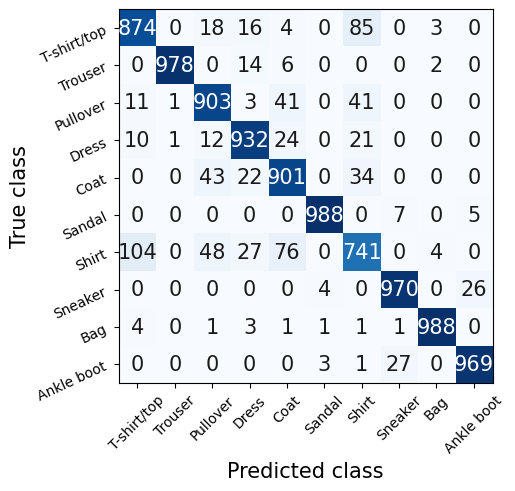

In [ ]:
metric_1 = Accuracy(task='multiclass', num_classes=10).to(device)
train_dataset = FashionMNIST(root='data', train=True, download=True, transform=T.ToTensor())
metric_2 = ConfusionMatrix(task='multiclass', num_classes=10).to(device)

model.eval()
with torch.inference_mode():
  for X_test, y_test in test_loader:
    X_test, y_test = X_test.to(device), y_test.to(device)
    y_pred = model(X_test)
    metric_1.update(y_pred, y_test)
    metric_2.update(y_pred, y_test)

print(metric_1.compute().item())
fig, ax = metric_2.plot(cmap='Blues', labels=train_dataset.classes)
plt.show()

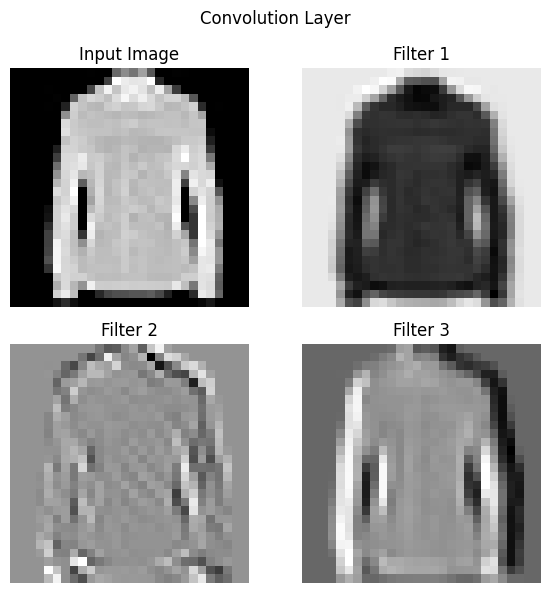

In [ ]:
model.eval()
img, label = next(iter(test_loader))
sample_img = img[26].unsqueeze(0).to(device)
block1_relu = model.layers[0][0:1]

with torch.inference_mode():
  feature_maps = block1_relu(sample_img).squeeze(0)

fig, ax = plt.subplots(2, 2, figsize=(6, 6))
plt.suptitle('Convolution Layer')
ax = ax.ravel()
ax[0].imshow(sample_img[0].cpu().squeeze(0), cmap='gray')
ax[0].set_title('Input Image')
ax[0].axis('off')
for i in range(1, 4):
  ax[i].imshow(feature_maps[i].cpu().numpy(), cmap='gray')
  ax[i].set_title(f'Filter {i}')
  ax[i].axis('off')
plt.tight_layout()
plt.show()


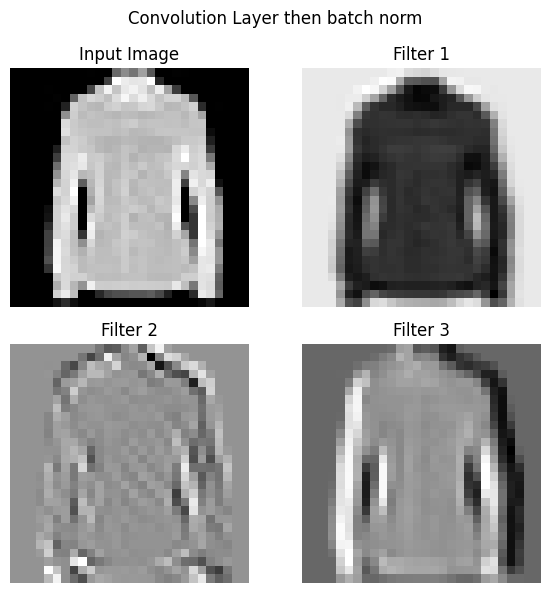

In [ ]:
model.eval()
img, label = next(iter(test_loader))
sample_img = img[26].unsqueeze(0).to(device)
block1_relu = model.layers[0][:2]

with torch.inference_mode():
  feature_maps = block1_relu(sample_img).squeeze(0)

fig, ax = plt.subplots(2, 2, figsize=(6, 6))
plt.suptitle('Convolution Layer then batch norm')
ax = ax.ravel()
ax[0].imshow(sample_img[0].cpu().squeeze(0), cmap='gray')
ax[0].set_title('Input Image')
ax[0].axis('off')
for i in range(1, 4):
  ax[i].imshow(feature_maps[i].cpu().numpy(), cmap='gray')
  ax[i].set_title(f'Filter {i}')
  ax[i].axis('off')
plt.tight_layout()
plt.show()


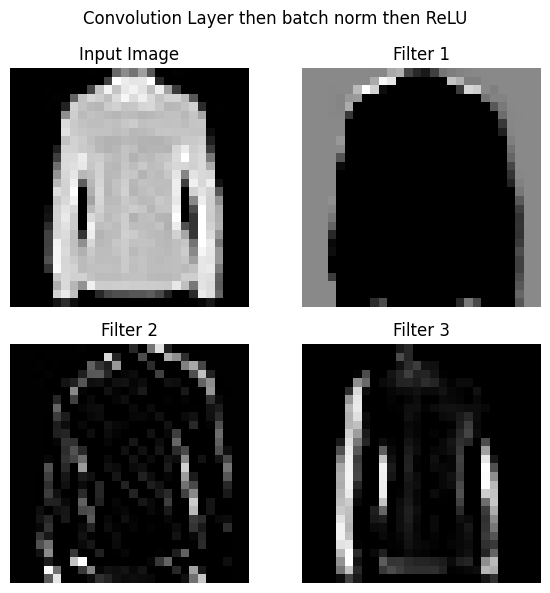

In [ ]:
model.eval()
img, label = next(iter(test_loader))
sample_img = img[26].unsqueeze(0).to(device)
block1_relu = model.layers[0][:3]

with torch.inference_mode():
  feature_maps = block1_relu(sample_img).squeeze(0)

fig, ax = plt.subplots(2, 2, figsize=(6, 6))
plt.suptitle('Convolution Layer then batch norm then ReLU')
ax = ax.ravel()
ax[0].imshow(sample_img[0].cpu().squeeze(0), cmap='gray')
ax[0].set_title('Input Image')
ax[0].axis('off')
for i in range(1, 4):
  ax[i].imshow(feature_maps[i].cpu().numpy(), cmap='gray')
  ax[i].set_title(f'Filter {i}')
  ax[i].axis('off')
plt.tight_layout()
plt.show()


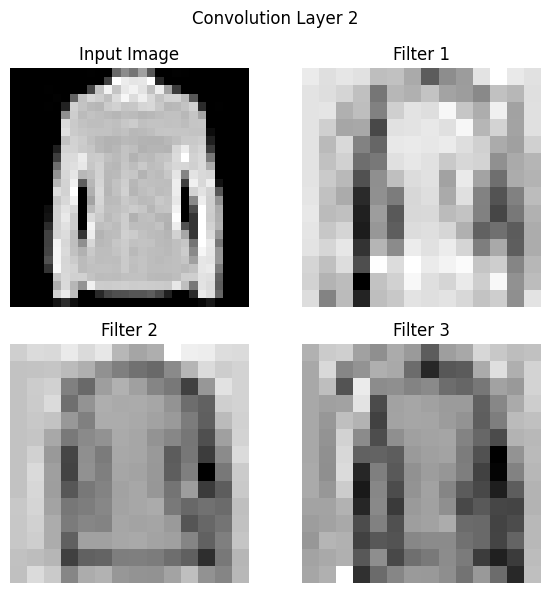

In [ ]:
model.eval()
img, label = next(iter(test_loader))
sample_img = img[26].unsqueeze(0).to(device)

conv2 = nn.Sequential(
    model.layers[0],
    model.layers[1][:2]
)

with torch.inference_mode():
  feature_maps = conv2(sample_img).squeeze(0)

fig, ax = plt.subplots(2, 2, figsize=(6, 6))
plt.suptitle('Convolution Layer 2')
ax = ax.ravel()
ax[0].imshow(sample_img[0].cpu().squeeze(0), cmap='gray')
ax[0].set_title('Input Image')
ax[0].axis('off')
for i in range(1, 4):
  ax[i].imshow(feature_maps[i].cpu().numpy(), cmap='gray')
  ax[i].set_title(f'Filter {i}')
  ax[i].axis('off')
plt.tight_layout()
plt.show()


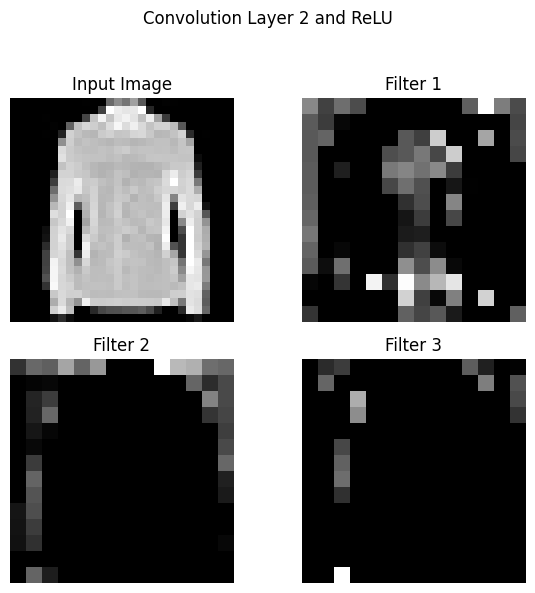

In [ ]:
model.eval()
img, label = next(iter(test_loader))
sample_img = img[26].unsqueeze(0).to(device)

conv2 = nn.Sequential(
    model.layers[0],
    model.layers[1][:3]
)

with torch.inference_mode():
  feature_maps = conv2(sample_img).squeeze(0)

fig, ax = plt.subplots(2, 2, figsize=(6, 6))
plt.suptitle('Convolution Layer 2 and ReLU')
ax = ax.ravel()
ax[0].imshow(sample_img[0].cpu().squeeze(0), cmap='gray')
ax[0].set_title('Input Image')
ax[0].axis('off')
for i in range(1, 4):
  ax[i].imshow(feature_maps[i].cpu().numpy(), cmap='gray')
  ax[i].set_title(f'Filter {i}')
  ax[i].axis('off')
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


In [ ]:
nn.Sequential(
    model.layers[0],
    model.layers[1][:3]
)

Sequential(
  (0): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=same, bias=False)
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (1): Sequential(
    (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=same, bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
  )
)